# SMS NLP Analysis

## Overview

This project analyzes SMS messages using Natural Language Processing (NLP) techniques.

The goals of this analysis are to:

- Explore SMS communication patterns
- Clean and preprocess text data
- Analyze message lengths
- Identify frequently used words
- Visualize text trends
- Perform sentiment analysis
- Extract named entities
- Measure message similarity

Dataset: NUS SMS Corpus

# 1. Import Libraries

Import the libraries required for data manipulation, visualization, and natural language processing.

In [3]:
import sys
import os

project_root = os.path.abspath("..")

if project_root not in sys.path:
    sys.path.append(project_root)

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from collections import Counter

from src.preprocess import preprocess_text

In [30]:
import nltk

nltk.download("punkt")
nltk.download("stopwords")
nltk.download("wordnet")
nltk.download("vader_lexicon")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\wayne\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\wayne\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\wayne\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\wayne\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\wayne\AppData\Roaming\nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


True

# 2. Load Dataset

Load the SMS dataset and inspect the first few records.

In [4]:
df = pd.read_csv("../data/clean_nus_sms.csv")

df.head()

,Unnamed: 0,id,Message,length,country,Date
0,0,10120,Bugis oso near wat...,21,SG,2003/4
1,1,10121,"Go until jurong point, crazy.. Available only ...",111,SG,2003/4
2,2,10122,I dunno until when... Lets go learn pilates...,46,SG,2003/4
3,3,10123,Den only weekdays got special price... Haiz......,140,SG,2003/4
4,4,10124,Meet after lunch la...,22,SG,2003/4


# 3. Dataset Overview

Examine the dataset dimensions, column names, and data types.

In [6]:
print("Shape:", df.shape)

Shape: (48598, 6)


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48598 entries, 0 to 48597
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  48598 non-null  int64
 1   id          48598 non-null  int64
 2   Message     48595 non-null  str  
 3   length      48598 non-null  str  
 4   country     48598 non-null  str  
 5   Date        48598 non-null  str  
dtypes: int64(2), str(4)
memory usage: 2.2 MB


In [8]:
df.columns.tolist()

['Unnamed: 0', 'id', 'Message', 'length', 'country', 'Date']

# 4. Data Cleaning

Remove unnecessary columns and handle missing values.

In [9]:
df = df.drop(columns=["Unnamed: 0"])

df = df.dropna(subset=["Message"])

df = df.reset_index(drop=True)

print(df.shape)

(48595, 5)


In [10]:
df.isnull().sum()

id         0
Message    0
length     0
country    0
Date       0
dtype: int64

# 5. Message Length Analysis

Analyze the distribution of SMS message lengths.

In [11]:
df["length"] = pd.to_numeric(
    df["length"],
    errors="coerce"
)

In [12]:
df["length"].describe()

count    48591.000000
mean        54.853594
std         53.203152
min          1.000000
25%         21.000000
50%         39.000000
75%         70.000000
max        910.000000
Name: length, dtype: float64

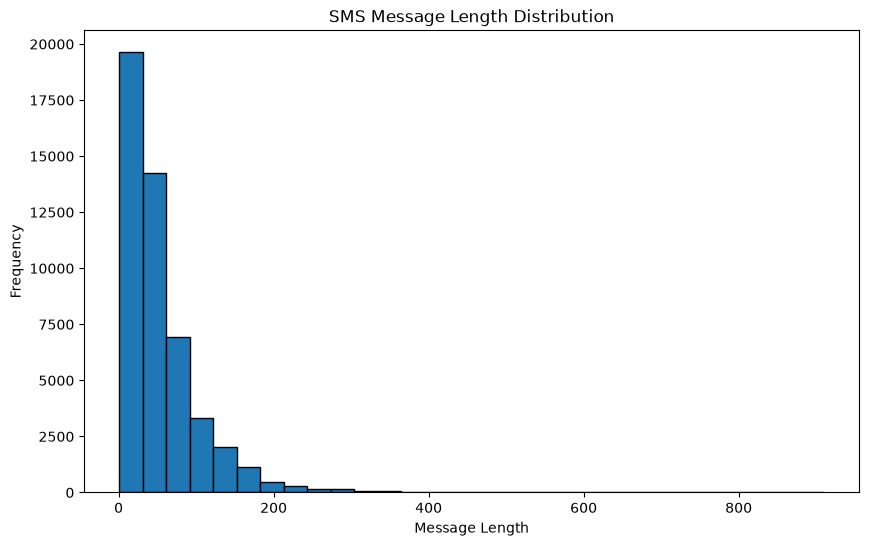

In [13]:
plt.figure(figsize=(10,6))

plt.hist(
    df["length"],
    bins=30,
    edgecolor="black"
)

plt.title("SMS Message Length Distribution")
plt.xlabel("Message Length")
plt.ylabel("Frequency")

plt.show()

# 6. Text Preprocessing

Apply the custom preprocessing pipeline to clean and tokenize SMS messages.

In [14]:
df["tokens"] = df["Message"].apply(preprocess_text)


In [15]:
df[["Message", "tokens"]].head()

,Message,tokens
0,Bugis oso near wat...,"[bugis, oso, near, wat]"
1,"Go until jurong point, crazy.. Available only ...","[go, jurong, point, crazy, available, bugis, n..."
2,I dunno until when... Lets go learn pilates...,"[dunno, let, go, learn, pilate]"
3,Den only weekdays got special price... Haiz......,"[den, weekday, got, special, price, haiz, cant..."
4,Meet after lunch la...,"[meet, lunch, la]"


# 7. Word Frequency Analysis

Identify the most common words appearing in SMS messages.

In [16]:
all_words = []

for tokens in df["tokens"]:
    all_words.extend(tokens)

word_counts = Counter(all_words)

In [17]:
top_20_words = word_counts.most_common(20)

top_20_words

[('u', 10377),
 ('haha', 6529),
 ('go', 3354),
 ('lol', 3000),
 ('got', 2590),
 ('im', 2329),
 ('ok', 2266),
 ('time', 2077),
 ('okay', 1694),
 ('ur', 1671),
 ('hahaha', 1667),
 ('one', 1562),
 ('going', 1543),
 ('le', 1496),
 ('oh', 1469),
 ('hey', 1461),
 ('like', 1431),
 ('come', 1421),
 ('get', 1419),
 ('think', 1418)]

In [18]:
top_words_df = pd.DataFrame(
    top_20_words,
    columns=["Word", "Frequency"]
)

top_words_df

,Word,Frequency
0,u,10377
1,haha,6529
2,go,3354
3,lol,3000
4,got,2590
5,im,2329
6,ok,2266
7,time,2077
8,okay,1694
9,ur,1671


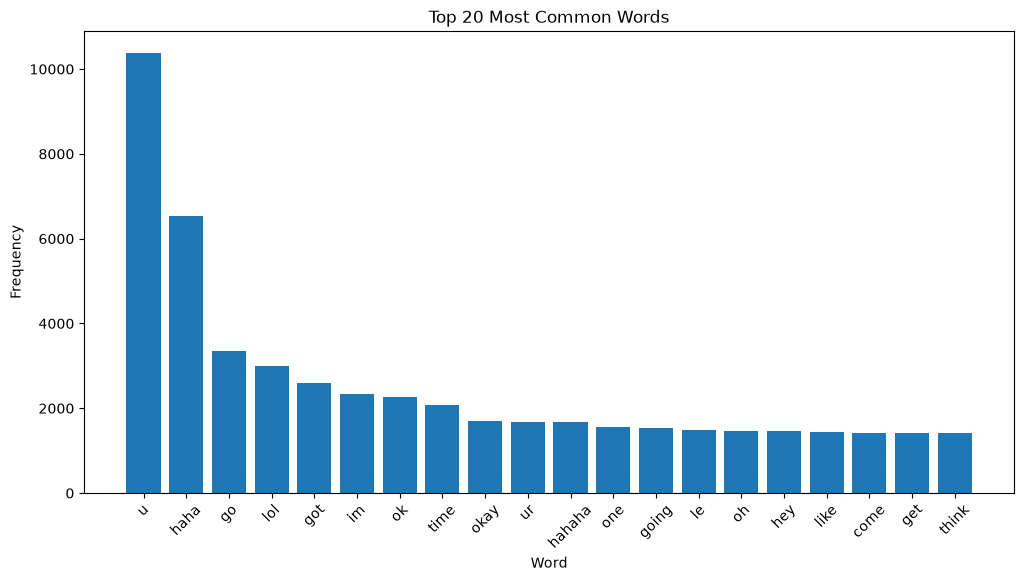

In [19]:
plt.figure(figsize=(12,6))

plt.bar(
    top_words_df["Word"],
    top_words_df["Frequency"]
)

plt.xticks(rotation=45)

plt.title("Top 20 Most Common Words")
plt.xlabel("Word")
plt.ylabel("Frequency")

plt.show()

# 8. Word Cloud

A word cloud provides a visual representation of the most frequently occurring words in the SMS corpus.

Words that appear more often are displayed in larger font sizes, making it easy to identify dominant themes and terms.

In [20]:
from wordcloud import WordCloud


In [21]:
text = " ".join(all_words)

print(text[:500])

bugis oso near wat go jurong point crazy available bugis n great world la e buffet cine got amore wat dunno let go learn pilate den weekday got special price haiz cant eat liao cut nail oso muz wait finish drivin wat lunch still muz eat wat meet lunch la walking citylink faster come hungry nightswe nt staying port step liaotoo ex hey pple nightsexcellent location wif breakfast hamper yun ahthe ubi one say wan call tomorrowcall look ireneere got bus ubi cresubi tech parkph st wkg daysn hey tmr ma


In [22]:
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis"
).generate(text)

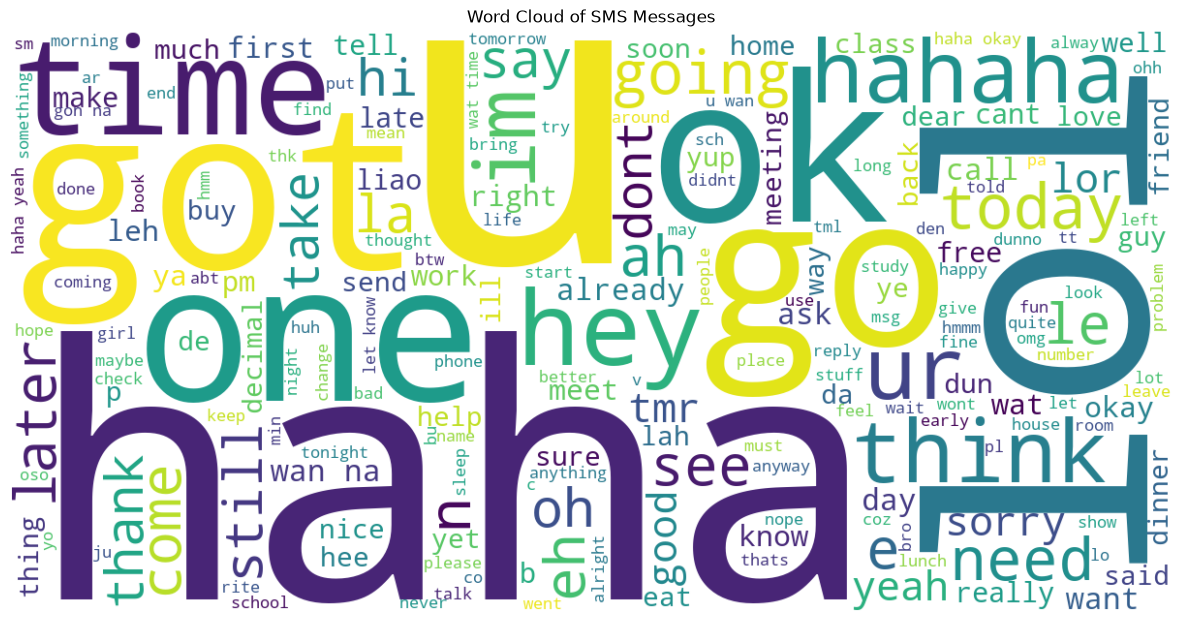

In [23]:
plt.figure(figsize=(15, 8))

plt.imshow(wordcloud, interpolation="bilinear")

plt.axis("off")

plt.title("Word Cloud of SMS Messages")

plt.show()

In [24]:
wordcloud.to_file("../images/wordcloud.png")

In [25]:
import os

os.path.exists("../images/wordcloud.png")


True

## Observations

The word cloud highlights the informal nature of SMS communication.

Common terms such as *haha*, *hey*, *ok*, and *sorry* suggest frequent social and conversational exchanges. Words including *today*, *going*, *call*, *time*, and *meet* indicate that many messages are used for planning and coordinating activities.

Several Singaporean colloquial terms such as *lor*, *leh*, and *liao* appear prominently, reflecting the regional characteristics of the NUS SMS Corpus.

Overall, the visualization suggests that the dataset primarily contains casual, relationship-focused communication rather than formal or business-oriented messaging.

# 9. Sentiment Analysis

Sentiment analysis measures the emotional tone of text.

In this section, the VADER sentiment analyzer from NLTK is used to classify messages as positive, neutral, or negative.

In [26]:
from nltk.sentiment import SentimentIntensityAnalyzer

In [28]:
import nltk

nltk.download("vader_lexicon")

[nltk_data] Downloading package vader_lexicon to
[nltk_data]     C:\Users\wayne\AppData\Roaming\nltk_data...


True

In [29]:
sia = SentimentIntensityAnalyzer()

In [31]:
df["sentiment_score"] = df["Message"].apply(
    lambda text: sia.polarity_scores(str(text))["compound"]
)

In [32]:
def classify_sentiment(score):

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


df["sentiment"] = df["sentiment_score"].apply(
    classify_sentiment
)

In [33]:
df[["Message", "sentiment_score", "sentiment"]].head()

,Message,sentiment_score,sentiment
0,Bugis oso near wat...,0.0000,Neutral
1,"Go until jurong point, crazy.. Available only ...",0.6249,Positive
2,I dunno until when... Lets go learn pilates...,0.0000,Neutral
3,Den only weekdays got special price... Haiz......,0.5445,Positive
4,Meet after lunch la...,0.0000,Neutral


In [34]:
sentiment_counts = df["sentiment"].value_counts()

sentiment_counts

sentiment
Positive    21488
Neutral     21426
Negative     5681
Name: count, dtype: int64

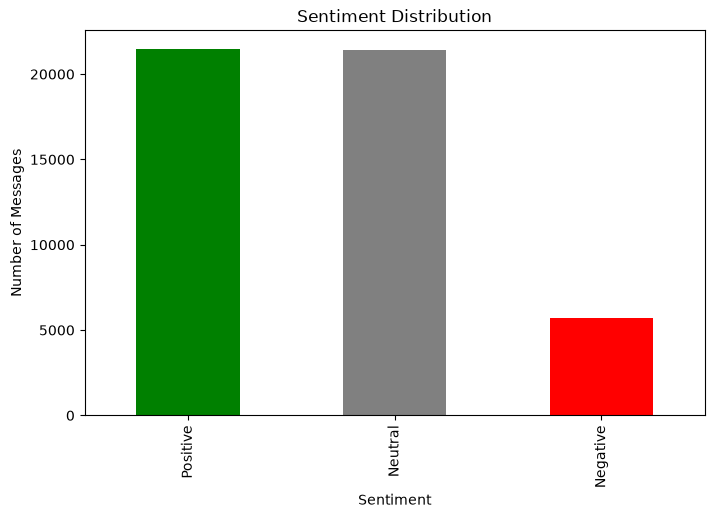

In [35]:
plt.figure(figsize=(8,5))

sentiment_counts.plot(
    kind="bar",
    color=["green", "gray", "red"]
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Messages")

plt.show()


In [36]:
(
    df["sentiment"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

sentiment
Positive    44.22
Neutral     44.09
Negative    11.69
Name: proportion, dtype: float64

## Observations

Sentiment analysis revealed that the majority of messages were either positive or neutral.

Positive messages accounted for 44.22% of the dataset, while neutral messages represented 44.09%. Only 11.69% of messages were classified as negative.

This suggests that SMS messaging is primarily used for everyday communication, social interaction, and coordination rather than conflict or negative exchanges. The relatively high proportion of positive messages is consistent with the frequent appearance of friendly and conversational terms observed in the word frequency and word cloud analyses.

# 10. Named Entity Recognition (NER)

Named Entity Recognition (NER) identifies important entities within text such as:

- People
- Organizations
- Locations
- Dates
- Times

This helps reveal the types of real-world entities that appear most frequently in SMS conversations.

In [38]:
import spacy

nlp = spacy.load("en_core_web_sm")

In [39]:
sample_text = df["Message"].iloc[0]

print(sample_text)

Bugis oso near wat...


In [40]:
doc = nlp(sample_text)

for ent in doc.ents:
    print(ent.text, ent.label_)

In [41]:
from collections import Counter

entity_counter = Counter()

sample_messages = df["Message"].head(5000)

In [42]:
for message in sample_messages:

    doc = nlp(str(message))

    for ent in doc.ents:
        entity_counter[(ent.text, ent.label_)] += 1

In [43]:
entity_counter.most_common(20)

[(('2', 'CARDINAL'), 292),
 (('4', 'CARDINAL'), 180),
 (('today', 'DATE'), 112),
 (('first', 'ORDINAL'), 92),
 (('Wat', 'PERSON'), 59),
 (('one', 'CARDINAL'), 55),
 (('tonight', 'TIME'), 51),
 (('dun', 'PERSON'), 39),
 (('Ya', 'PERSON'), 38),
 (('U', 'ORG'), 33),
 (('1', 'CARDINAL'), 30),
 (('Hee', 'PERSON'), 29),
 (('5', 'CARDINAL'), 26),
 (('tomorrow', 'DATE'), 26),
 (('10', 'CARDINAL'), 25),
 (('Dun', 'ORG'), 23),
 (('Wah', 'PERSON'), 22),
 (('3', 'CARDINAL'), 22),
 (('Den', 'PERSON'), 18),
 (('6', 'CARDINAL'), 18)]

In [44]:
entities_df = pd.DataFrame(
    entity_counter.most_common(20),
    columns=["Entity", "Frequency"]
)

entities_df

,Entity,Frequency
0,"(2, CARDINAL)",292
1,"(4, CARDINAL)",180
2,"(today, DATE)",112
3,"(first, ORDINAL)",92
4,"(Wat, PERSON)",59
5,"(one, CARDINAL)",55
6,"(tonight, TIME)",51
7,"(dun, PERSON)",39
8,"(Ya, PERSON)",38
9,"(U, ORG)",33


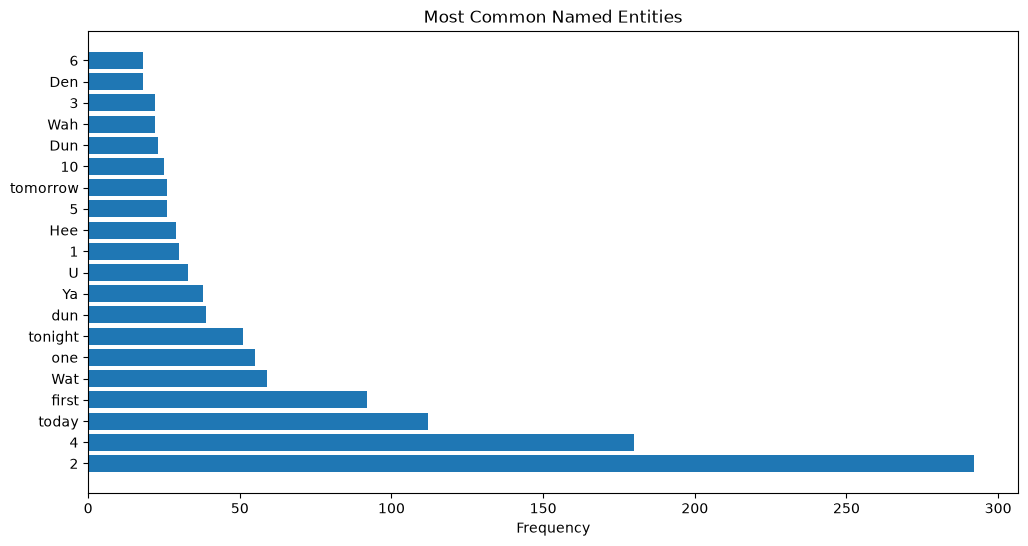

In [45]:
plt.figure(figsize=(12,6))

plt.barh(
    [str(x[0]) for x in entities_df["Entity"]],
    entities_df["Frequency"]
)

plt.title("Most Common Named Entities")
plt.xlabel("Frequency")

plt.show()

## Observations

Named Entity Recognition successfully identified several temporal entities such as dates, times, ordinal values, and numbers. Examples include "today", "tomorrow", and "tonight".

The model also produced several inaccurate classifications, identifying common SMS abbreviations and colloquial expressions as people or organizations. This highlights one limitation of applying NLP models trained on formal written text to highly informal SMS messages.

Overall, the results demonstrate both the usefulness and limitations of Named Entity Recognition when working with conversational messaging data.

# 11. Part-of-Speech (POS) Tagging

Part-of-Speech tagging assigns grammatical roles to words, such as:

- Nouns
- Verbs
- Adjectives
- Adverbs
- Pronouns

This analysis helps reveal how people structure their SMS conversations.

In [46]:
sample_message = df["Message"].iloc[0]

print(sample_message)


Bugis oso near wat...


In [47]:
doc = nlp(sample_message)

for token in doc:
    print(token.text, token.pos_)

Bugis NOUN
oso NOUN
near ADP
wat NOUN
... PUNCT


In [48]:
from collections import Counter

pos_counts = Counter()

sample_messages = df["Message"].head(5000)

In [49]:
for message in sample_messages:

    doc = nlp(str(message))

    for token in doc:
        pos_counts[token.pos_] += 1

In [50]:
pos_counts.most_common()

[('PUNCT', 10120),
 ('NOUN', 9973),
 ('VERB', 8716),
 ('PRON', 6665),
 ('PROPN', 6227),
 ('ADV', 4242),
 ('ADP', 3072),
 ('ADJ', 2751),
 ('AUX', 2683),
 ('INTJ', 1632),
 ('NUM', 1444),
 ('PART', 1373),
 ('DET', 1355),
 ('SCONJ', 1076),
 ('CCONJ', 768),
 ('X', 245),
 ('SYM', 42)]

In [51]:
pos_df = pd.DataFrame(
    pos_counts.items(),
    columns=["POS", "Count"]
)

pos_df = pos_df.sort_values(
    by="Count",
    ascending=False
)

pos_df

,POS,Count
2,PUNCT,10120
0,NOUN,9973
3,VERB,8716
8,PRON,6665
4,PROPN,6227
6,ADV,4242
1,ADP,3072
5,ADJ,2751
10,AUX,2683
13,INTJ,1632


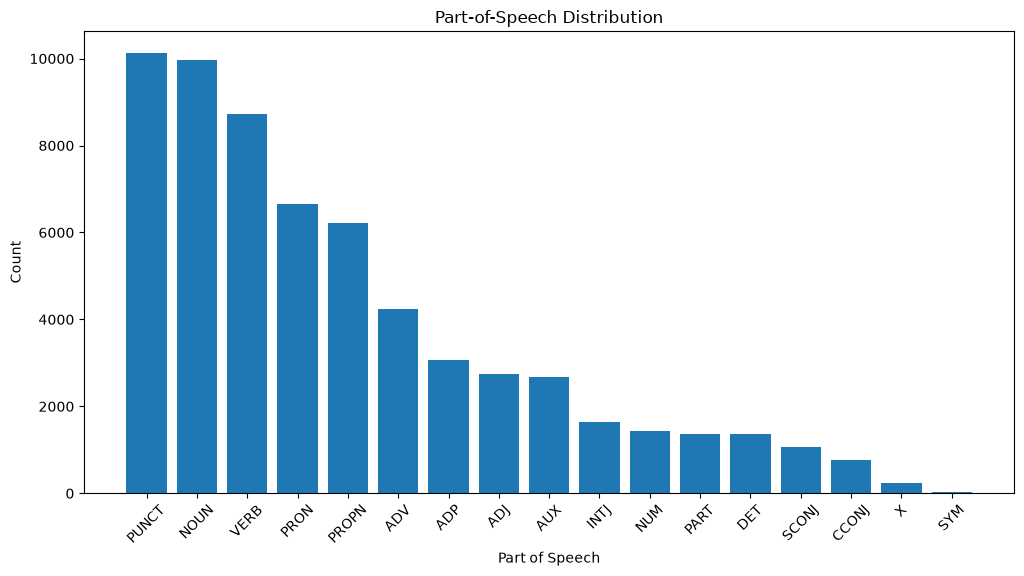

In [52]:
plt.figure(figsize=(12,6))

plt.bar(
    pos_df["POS"],
    pos_df["Count"]
)

plt.xticks(rotation=45)

plt.title("Part-of-Speech Distribution")
plt.xlabel("Part of Speech")
plt.ylabel("Count")

plt.show()

## Observations

The POS analysis reveals the grammatical composition of SMS conversations.

High frequencies of pronouns, verbs, and nouns suggest that most messages are conversational and action-oriented. The prevalence of informal language and abbreviations may influence tagging accuracy, but overall the results provide insight into how users communicate through text messages.

In [53]:
pos_counts.most_common(15)

[('PUNCT', 10120),
 ('NOUN', 9973),
 ('VERB', 8716),
 ('PRON', 6665),
 ('PROPN', 6227),
 ('ADV', 4242),
 ('ADP', 3072),
 ('ADJ', 2751),
 ('AUX', 2683),
 ('INTJ', 1632),
 ('NUM', 1444),
 ('PART', 1373),
 ('DET', 1355),
 ('SCONJ', 1076),
 ('CCONJ', 768)]

## Observations

Part-of-Speech analysis indicates that SMS messages are highly conversational and action-oriented.

Nouns and verbs were the most common grammatical categories, suggesting that users primarily exchange information, discuss activities, and coordinate plans.

The high frequency of pronouns reflects the personal nature of SMS communication, while numerous interjections such as informal expressions and laughter indicate a relaxed conversational style.

Additionally, the prevalence of numerical terms supports earlier findings that many messages involve scheduling, dates, times, and quantities.

# 12. Text Similarity Analysis

Text similarity analysis measures how alike two messages are.

Using TF-IDF vectorization and cosine similarity, SMS messages can be represented numerically and compared mathematically.

In [54]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


In [55]:
sample_df = df.head(1000).copy()

In [56]:
vectorizer = TfidfVectorizer()

tfidf_matrix = vectorizer.fit_transform(
    sample_df["Message"].astype(str)
)

print(tfidf_matrix.shape)


(1000, 1509)


In [57]:
similarity_matrix = cosine_similarity(
    tfidf_matrix
)

In [58]:
import numpy as np

np.fill_diagonal(similarity_matrix, 0)

max_index = np.unravel_index(
    similarity_matrix.argmax(),
    similarity_matrix.shape
)

max_index

(np.int64(175), np.int64(723))

In [59]:
i, j = max_index

print("Similarity Score:")
print(similarity_matrix[i, j])

print("\nMessage 1:")
print(sample_df.iloc[i]["Message"])

print("\nMessage 2:")
print(sample_df.iloc[j]["Message"])

Similarity Score:
1.0000000000000002

Message 1:
Wat ü doing now?

Message 2:
Wat r u doing now?


## Observations

TF-IDF vectorization converts SMS messages into numerical representations based on word importance.

Cosine similarity was used to identify messages with similar content. Messages with higher similarity scores generally discussed the same topics or contained similar wording.

This technique can be useful for clustering messages, detecting duplicates, or building recommendation and search systems.

# 13. Conclusions and Future Improvements

## Project Summary

This project analyzed 48,595 SMS messages from the NUS SMS Corpus using a range of Natural Language Processing (NLP) techniques.

The analysis included:

- Data cleaning and preprocessing
- Message length analysis
- Word frequency analysis
- Word cloud visualization
- Sentiment analysis
- Named Entity Recognition (NER)
- Part-of-Speech (POS) tagging
- Text similarity analysis using TF-IDF and cosine similarity

These techniques were used to gain insight into communication patterns and language usage within SMS messages.

## Key Findings

### Dataset Characteristics

After removing missing values, the dataset contained 48,595 valid SMS messages.

Message lengths varied considerably, although most messages were relatively short, reflecting the concise nature of SMS communication.

### Word Frequency and Word Cloud

The most common words included:

- haha
- hey
- ok
- time
- today
- going
- think

The results indicate that SMS conversations are largely informal and focused on social interaction, planning, and coordination.

Several Singaporean colloquial terms such as "lor", "leh", and "liao" were also prominent, reflecting the regional origins of the dataset.

### Sentiment Analysis

Sentiment analysis revealed the following distribution:

| Sentiment | Percentage |
|------------|-----------:|
| Positive | 44.22% |
| Neutral | 44.09% |
| Negative | 11.69% |

The results suggest that SMS communication is generally neutral or positive, with relatively few negative interactions.

### Named Entity Recognition

The NER model successfully identified several temporal entities, including dates, times, and quantities.

However, some informal SMS terms were incorrectly classified as named entities. This highlights the limitations of applying models trained on formal written language to highly informal text messages.

### Part-of-Speech Analysis

The most common parts of speech were:

- Nouns
- Verbs
- Pronouns
- Proper nouns

This suggests that SMS communication is highly conversational and action-oriented, with users frequently discussing people, activities, and plans.

### Text Similarity Analysis

TF-IDF vectorization and cosine similarity successfully identified messages with similar content.

This demonstrates how text can be transformed into numerical representations that support search, clustering, and recommendation systems.

## Limitations

Several limitations should be considered when interpreting the results.

1. SMS messages contain abbreviations, slang, and spelling variations that can affect NLP accuracy.

2. Sentiment analysis may not always correctly interpret sarcasm, humor, or informal language.

3. Named Entity Recognition was trained primarily on formal text and therefore struggled with some SMS-specific vocabulary.

4. Only a subset of messages was used during some advanced analyses to reduce processing time.

## Future Improvements

Future enhancements could include:

- Topic Modeling using Latent Dirichlet Allocation (LDA)
- Word Embeddings using Word2Vec
- Message Clustering
- SMS Category Classification
- Deep Learning Sentiment Analysis
- Interactive Dashboard Development
- Real-Time SMS Analysis Pipeline

These improvements would provide deeper insights into communication patterns and further demonstrate advanced NLP capabilities.

## Final Reflection

This project demonstrated how Natural Language Processing techniques can be used to extract useful information from unstructured text data.

Through preprocessing, sentiment analysis, entity recognition, grammatical analysis, and similarity measurement, it was possible to identify patterns and insights within a large collection of SMS messages.

The project also highlighted the challenges associated with analyzing informal conversational text and the importance of selecting appropriate NLP tools for specific domains.